# Week 3: Volatility
Treating volatility as a static constant is the most common beginner error.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

TICKERS = ["TLT", "SHY"] 

data = {}
for ticker in TICKERS:
    data[ticker] = pd.read_csv(f"../data/{ticker}.csv", index_col=0, parse_dates=True)
    print(ticker, "saved:", len(data[ticker]), "days")

data["TLT"].tail() #view last 5 rows as an example

TLT saved: 2514 days
SHY saved: 2514 days


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2025-12-24,85.062859,88.029999,88.080002,87.650002,87.760002,25942000
2025-12-26,84.782639,87.739998,88.169998,87.599998,88.099998,26522700
2025-12-29,85.101509,88.070000,88.070000,87.790001,87.949997,29399800
2025-12-30,84.898582,87.860001,88.040001,87.669998,87.739998,25106800
2025-12-31,84.222176,87.160004,87.910004,87.129997,87.680000,36500000


## Visual
Plot the **21-day rolling annualized volatility** for both assets. Mark the **three highest spikes** and
identify the real-world events that caused them. (You'll have to calculate it from returns which you found in week 1)

TLT 2020-03-27 61.36%
TLT 2023-11-09 25.70%
TLT 2022-12-09 25.60%
SHY 2023-03-29 6.07%
SHY 2020-03-27 3.56%
SHY 2022-07-06 3.54%


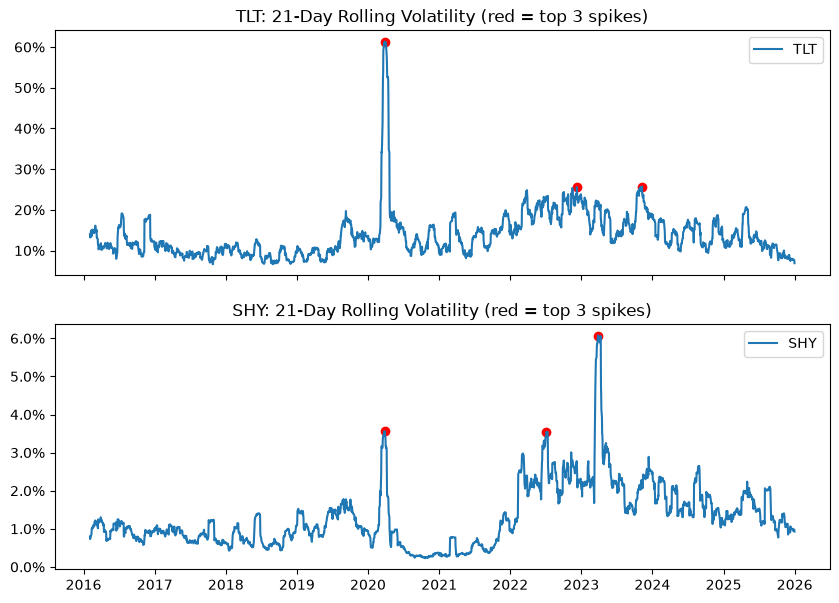

In [ ]:
from matplotlib.ticker import PercentFormatter

# Step 1: Rebuild daily returns from Adjusted Close (same method as Week 1)
prices = pd.DataFrame({ticker: data[ticker]["Adj Close"] for ticker in TICKERS})
returns = prices.pct_change().dropna()

# Step 2: Calculate 21-day rolling annualized volatility (21 trading days ≈ 1 month)
WINDOW = 21
rolling_vol = returns.rolling(WINDOW).std() * np.sqrt(252)

# Step 2: Find the three highest *distinct* spikes
def top_spikes(series, n=3, gap_days=90):
    s = series.dropna()
    spikes = []
    for _ in range(n):
        peak_date = s.idxmax()  # date of the highest remaining value
        spikes.append((peak_date, s[peak_date]))
        # Drop anything within gap_days of this peak, so the next pick is a different episode
        too_close = abs(s.index - peak_date) <= pd.Timedelta(days=gap_days)
        s = s[~too_close]
    return spikes

# Step 3: Plot each asset in its own panel and mark the spikes
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for ax, ticker in zip(axes, TICKERS):
    ax.plot(rolling_vol[ticker], label=ticker)

    for date, vol in top_spikes(rolling_vol[ticker]):
        ax.scatter(date, vol, color="red")
        print(ticker, date.date(), f"{vol:.2%}")

    ax.set_title(f"{ticker}: 21-Day Rolling Volatility (red = top 3 spikes)")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend()

plt.show()


| Asset | Spike date | Event |
|---|---|---|
| [FILL IN] | [FILL IN] | [FILL IN] |
| | | |

## The Check
Test for volatility clustering by plotting the **autocorrelation of absolute returns**
(proving that "big days follow big days").

TLT: |r| lag-1 = 0.28, raw lag-1 = -0.02, |r| lags above band: 50 of 50
SHY: |r| lag-1 = 0.32, raw lag-1 = -0.04, |r| lags above band: 50 of 50


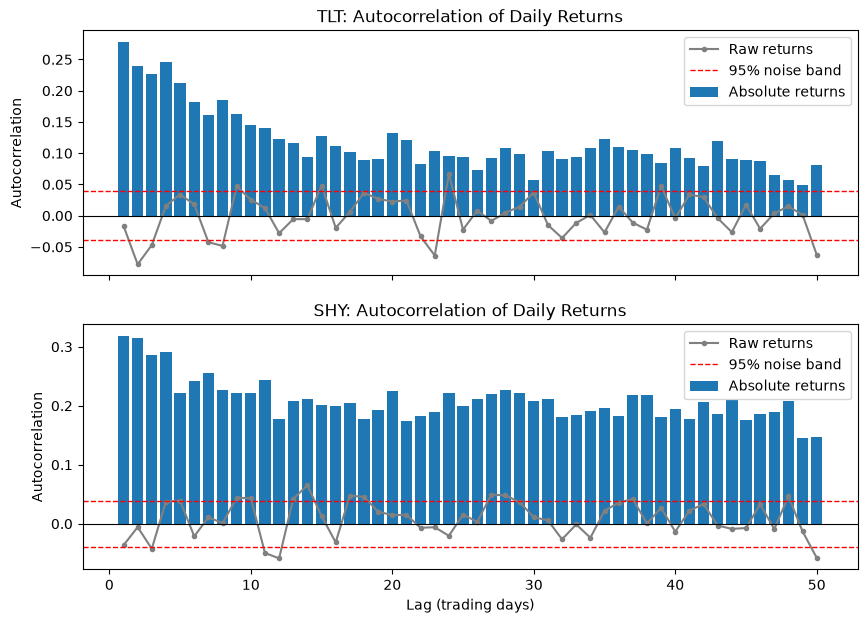

In [12]:
# Step 1–2: Autocorrelation of raw vs absolute returns, lags 1–50 days
MAX_LAG = 50
lags = range(1, MAX_LAG + 1)

# Step 3: 95% noise band — autocorrelations inside this could just be chance
conf = 1.96 / np.sqrt(len(returns))

# Step 4: Plot each asset in its own panel
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

for ax, ticker in zip(axes, TICKERS):
    raw_acf = [returns[ticker].autocorr(lag) for lag in lags]
    abs_acf = [returns[ticker].abs().autocorr(lag) for lag in lags]

    ax.bar(lags, abs_acf, label="Absolute returns")
    ax.plot(lags, raw_acf, color="gray", marker=".", label="Raw returns")
    ax.axhline(conf, color="red", linestyle="--", linewidth=1, label="95% noise band")
    ax.axhline(-conf, color="red", linestyle="--", linewidth=1)
    ax.axhline(0, color="black", linewidth=0.8)

    ax.set_title(f"{ticker}: Autocorrelation of Daily Returns")
    ax.set_ylabel("Autocorrelation")
    ax.legend()

    print(f"{ticker}: |r| lag-1 = {abs_acf[0]:.2f}, raw lag-1 = {raw_acf[0]:.2f}, "
          f"|r| lags above band: {sum(a > conf for a in abs_acf)} of {MAX_LAG}")

axes[-1].set_xlabel("Lag (trading days)")
plt.show()


## The Paragraph
> **Does market panic hit both assets simultaneously, or do they experience isolated crises?**

Market panic hits both assets, but depends on what causes the panic. A market-wide shock hits both at once, for example, In March 2020, COVID pushed TLT's 21 day-volatility to 61.4% (4.4x its normal level) and SHY's to 3.56% (2.7x normal) in the same week. Shocks to one part of the yield curve mostly stays isolated. SHY follows expectations for the next few Fed moves, so its worst stretch came with the March 2023 SVB collapse (6.07%, 4.6x normal), while TLT rose only to 1.6x its normal level. TLT follows long-term inflation and Treasury supply, so the late-2023 long-bond selloff hit TLT harder. The two still share a common rate environment: their rolling volatilities have a correlation of 0.59, and both roughly doubled during the 2022-23 hiking cycle. Since colatility clusters for both assets, a crisis that reaches both tends to last for weeks. SHY offers the least protection when the panic is broad.

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 6: volatility"
git push
```